In [12]:
import matplotlib as mpl
import numpy as np
import pandas as pd
from pathlib import Path




In [13]:
path = "/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2025-12-05_11-19-29"
path = Path(path) / 'logs'

# Visualizations
This notebook loads `metrics.csv` from a run's `logs/` directory, displays the dataframe head, and plots common training metrics (loss, accuracy). It also saves figures to `logs/figures` if possible.

In [14]:
# Robustly locate the metrics file (uses existing `path` if defined)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
# If `path` already exists in the notebook namespace, use it; otherwise pick the latest run_*/logs
default_base = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output")
if 'path' not in globals():
    runs = sorted([p for p in default_base.iterdir() if p.is_dir() and p.name.startswith("run_")])
    if not runs:
        raise FileNotFoundError(f"No run_* directories in {default_base}")
    run_dir = runs[-1]
    print("Using latest run:", run_dir.name)
    path = run_dir
else:
    path = Path(path)

# locate logs dir and choose an appropriate CSV produced by MetricLogger
logs_dir = path / "logs" if (path / "logs").exists() else path
csv_files = sorted(logs_dir.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {logs_dir}")

# Prefer common filenames from MetricLogger; fallback to any CSV containing 'training' or 'metrics', else first CSV
preferred = [
    'train_training_metrics.csv',
    'test_training_metrics.csv',
    'train_metrics_per_graph.csv',
    'test_metrics_per_graph.csv',
    'train_metrics_per_query_type.csv',
    'test_metrics_per_query_type.csv',
    'final_test_metrics.csv',
    'metrics.csv'
]
metrics_file = None
for name in preferred:
    p = logs_dir / name
    if p.exists():
        metrics_file = p
        break

if metrics_file is None:
    for p in csv_files:
        if 'training' in p.name.lower() or 'metrics' in p.name.lower():
            metrics_file = p
            break

if metrics_file is None:
    metrics_file = csv_files[0]

print('Using metrics file:', metrics_file.name)

df = pd.read_csv(metrics_file)
display(df.head())
# Determine x-axis (prefer `epoch` or `step`)
if 'epoch' in df.columns:
    x = 'epoch'
elif 'step' in df.columns:
    x = 'step'
else:
    # fallback to index if no clear x column
    x = df.columns[0]

Using metrics file: train_training_metrics.csv


,epoch,loss,mse,mae,rmse,q_error
0,1,7.504817,1.380069e+16,1.192720e+07,1.174763e+08,377.128124
1,2,5.302430,1.809828e+16,1.293273e+07,1.345298e+08,110.393253
2,3,3.284742,1.382028e+16,1.198187e+07,1.175597e+08,32.449688
3,4,2.496930,1.055490e+16,1.060605e+07,1.027370e+08,20.941514
4,5,2.081921,1.466961e+16,1.168761e+07,1.211182e+08,27.968582


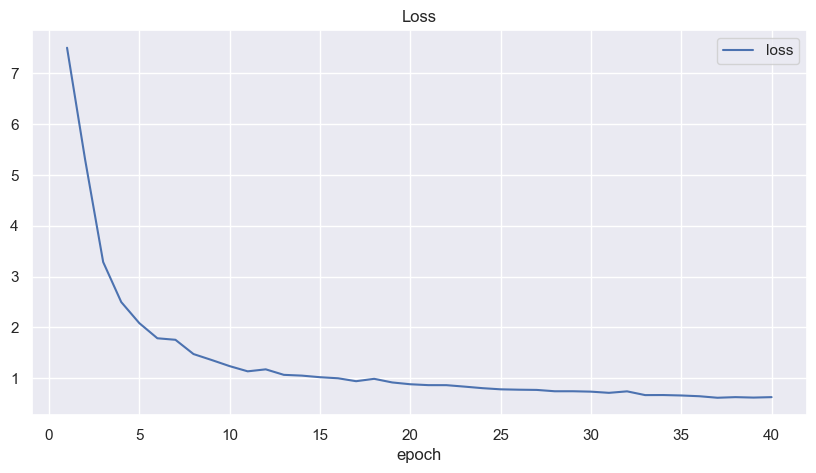

No columns found for Accuracy
Saved figures to /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2025-12-05_11-19-29/logs/figures


In [15]:
# Plot loss-like and accuracy-like columns (if present) and save figures
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({'figure.figsize': (10, 5)})
# heuristics to find columns
loss_cols = [c for c in df.columns if 'loss' in c.lower()]
acc_cols = [c for c in df.columns if 'acc' in c.lower() or 'accuracy' in c.lower()]
def plot_cols(cols, title):
    if not cols:
        print(f"No columns found for {title}")
        return
    fig, ax = plt.subplots()
    for c in cols:
        ax.plot(df[x], df[c], label=c)
    ax.set_xlabel(x)
    ax.set_title(title)
    ax.legend()
    plt.show()

plot_cols(loss_cols, 'Loss')
plot_cols(acc_cols, 'Accuracy')

# Save figures to logs/figures
out_fig_dir = logs_dir / 'figures'
out_fig_dir.mkdir(exist_ok=True)
for title, cols in [('loss', loss_cols), ('accuracy', acc_cols)]:
    if cols:
        fig, ax = plt.subplots()
        for c in cols:
            ax.plot(df[x], df[c], label=c)
        ax.set_xlabel(x)
        ax.set_title(title.capitalize())
        ax.legend()
        fig.savefig(out_fig_dir / f"{title}.png", bbox_inches='tight', dpi=150)
        plt.close(fig)
print('Saved figures to', out_fig_dir)

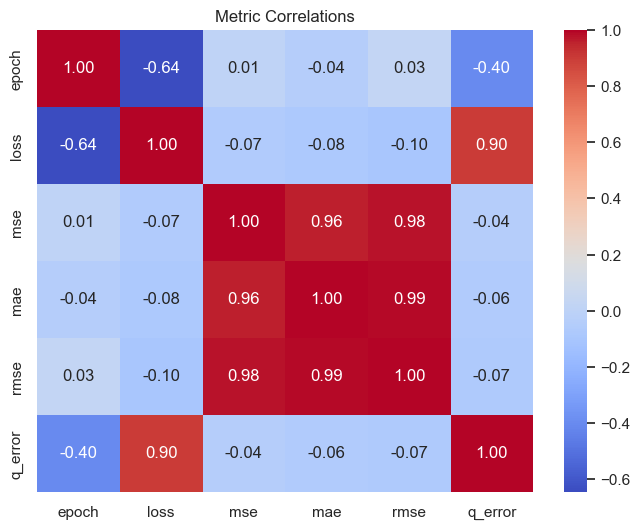

In [16]:
# Correlation heatmap of numeric metrics (if multiple numeric columns exist)
import numpy as np
num = df.select_dtypes(include=[np.number])
if num.shape[1] > 1:
    corr = num.corr()
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title("Metric Correlations")
    plt.show()
else:
    print("Not enough numeric columns for correlation heatmap.")

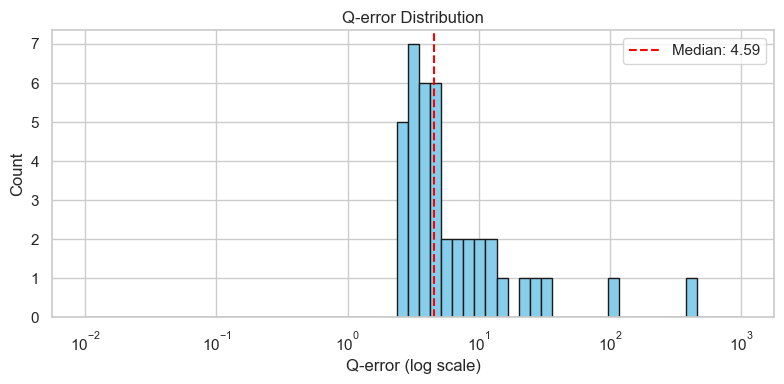

True values not available — skipping per-cardinality boxplots.


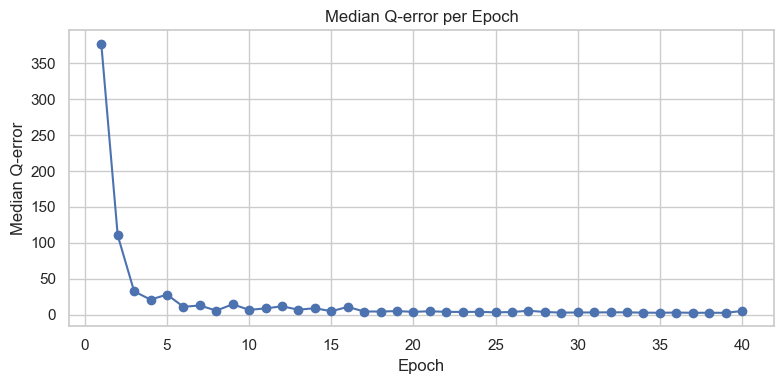

Predicted/true values not both available — skipping predicted vs true scatter.
Saved Q-error visualizations to /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2025-12-05_11-19-29/logs/figures


In [17]:
# Q-error visualizations: histogram, boxplots by cardinality, medians, and pred vs true scatter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

# Helper to load preds/true values from common column names
preds = None
trues = None
q_errors = None

# If q_error is already present (per-row), use it
if 'q_error' in df.columns:
    q_errors = df['q_error'].values
    if 'true_values' in df.columns:
        trues = df['true_values'].values
    elif 'true_values_log' in df.columns:
        trues = np.exp(df['true_values_log'].values)

# Try to find predictions/true columns if q_error missing
if q_errors is None:
    # direct names
    if 'predictions' in df.columns and 'true_values' in df.columns:
        preds = df['predictions'].values
        trues = df['true_values'].values
    elif 'predictions_log' in df.columns and 'true_values_log' in df.columns:
        preds = np.exp(df['predictions_log'].values)
        trues = np.exp(df['true_values_log'].values)
    else:
        # fuzzy search for columns containing 'pred' and 'true'
        pred_candidates = [c for c in df.columns if 'pred' in c.lower()]
        true_candidates = [c for c in df.columns if 'true' in c.lower()]
        if pred_candidates and true_candidates:
            preds = df[pred_candidates[0]].values
            trues = df[true_candidates[0]].values
            # if either looks like log (contains 'log' in name), exponentiate
            if 'log' in pred_candidates[0].lower():
                preds = np.exp(preds)
            if 'log' in true_candidates[0].lower():
                trues = np.exp(trues)

    if preds is not None and trues is not None:
        # avoid zeros
        eps = 1e-9
        preds_safe = np.maximum(preds, eps)
        trues_safe = np.maximum(trues, eps)
        q_errors = np.maximum(preds_safe / trues_safe, trues_safe / preds_safe)

if q_errors is None:
    print("No q_error or matching prediction/true columns found; skipping Q-error visualizations.")
else:
    # Ensure output directory exists
    out_fig_dir = logs_dir / 'figures'
    out_fig_dir.mkdir(exist_ok=True)

    # 1) Histogram of Q-errors (log-scaled x-axis for readability)
    fig, ax = plt.subplots(figsize=(8, 4))
    # use logspace bins for heavy-tailed q-errors
    bins = np.logspace(-2, 3, 60)  # 0.01 to 1000
    ax.hist(q_errors, bins=bins, color='skyblue', edgecolor='k')
    ax.set_xscale('log')
    ax.set_xlabel('Q-error (log scale)')
    ax.set_ylabel('Count')
    ax.set_title('Q-error Distribution')
    median_q = np.median(q_errors)
    ax.axvline(median_q, color='red', linestyle='--', label=f'Median: {median_q:.2f}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_fig_dir / 'q_error_hist.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # 2) Boxplots by cardinality bins (use true values if available)
    bins_def = [('<10', lambda t: t < 10),
                ('10-99', lambda t: (t >= 10) & (t < 100)),
                ('100-999', lambda t: (t >= 100) & (t < 1000)),
                ('1k-1M', lambda t: (t >= 1000) & (t < 1000000)),
                ('>=1M', lambda t: t >= 1000000)]

    if trues is not None:
        groups = []
        labels = []
        for label, mask_fn in bins_def:
            mask = mask_fn(trues)
            group = q_errors[mask]
            if group.size > 0:
                groups.append(group)
                labels.append(label)
            else:
                groups.append(np.array([]))
                labels.append(label)

        fig, ax = plt.subplots(figsize=(10, 5))
        # seaborn boxplot expects a list of arrays in recent versions -- use matplotlib directly
        ax.boxplot(groups, labels=labels, showfliers=False)
        ax.set_yscale('log')
        ax.set_ylabel('Q-error (log scale)')
        ax.set_title('Q-error by True Cardinality Bins (no outliers shown)')
        fig.tight_layout()
        fig.savefig(out_fig_dir / 'q_error_boxplot_by_bin.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close(fig)

        # 2b) Median per bin bar plot
        medians = [np.median(g) if g.size>0 else np.nan for g in groups]
        fig, ax = plt.subplots(figsize=(8,4))
        ax.bar(labels, medians, color='teal')
        ax.set_ylabel('Median Q-error')
        ax.set_title('Median Q-error by Cardinality Bin')
        for i, m in enumerate(medians):
            if not np.isnan(m):
                ax.text(i, m, f"{m:.2f}", ha='center', va='bottom')
        fig.tight_layout()
        fig.savefig(out_fig_dir / 'q_error_median_by_bin.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close(fig)
    else:
        print('True values not available — skipping per-cardinality boxplots.')

    # 3) Median (or provided q_error) trend over epochs if `epoch` exists
    if 'epoch' in df.columns:
        # if q_error column exists in df as aggregate per-epoch, use it; otherwise compute median per epoch from per-sample q_errors
        if 'q_error' in df.columns and len(df) > 1 and df['epoch'].nunique() > 1:
            # aggregated metrics per epoch
            epoch_med = df.groupby('epoch')['q_error'].median()
        else:
            # need per-sample epoch to compute median; assume q_errors aligned with df rows
            epoch_med = df.assign(q_error=q_errors).groupby('epoch')['q_error'].median()

        fig, ax = plt.subplots(figsize=(8,4))
        epoch_med.plot(marker='o', ax=ax)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Median Q-error')
        ax.set_title('Median Q-error per Epoch')
        fig.tight_layout()
        fig.savefig(out_fig_dir / 'q_error_median_per_epoch.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close(fig)
    else:
        print('No `epoch` column found — skipping epoch median plot.')

    # 4) Predicted vs True scatter (log-log) if preds/trues available
    if preds is not None and trues is not None:
        # Sample if too many points
        max_points = 5000
        idx = np.arange(len(preds))
        if len(idx) > max_points:
            rng = np.random.default_rng(0)
            idx = rng.choice(idx, size=max_points, replace=False)
        p_sample = preds[idx]
        t_sample = trues[idx]

        fig, ax = plt.subplots(figsize=(6,6))
        ax.scatter(t_sample, p_sample, alpha=0.3, s=10)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title('Predicted vs True (log-log)')
        # diagonal
        mn = min(t_sample.min(), p_sample.min())
        mx = max(t_sample.max(), p_sample.max())
        ax.plot([mn, mx], [mn, mx], color='red', linestyle='--')
        fig.tight_layout()
        fig.savefig(out_fig_dir / 'predicted_vs_true_scatter.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close(fig)
    else:
        print('Predicted/true values not both available — skipping predicted vs true scatter.')

    print('Saved Q-error visualizations to', out_fig_dir)
